# Predicting the beam on SightX from NEOARM readbacks

At MAG 40k, suppose CLA1 moves by +100 DAC along x. Which camera pixels does the beam cross? This notebook traces the column once with the original settings and once with the change. A real two-axis kick at 40k fixes the scale and orientation of that response. We then test both axes at other MAG rows.

The model starts from the 17 November console tables, the JEOL drawing and the saved projection fit in `neoarm_nondimensional.ipynb`. Those inputs describe the settings and provide a starting optical layout. Camera images supply the measured beam response. The companion fitting notebook uses calibration frames from an unknown instrument.

Run from the repository root or this folder with the TemGym Python environment. The real-data sections read the local `beam_per_magnification.zip`, `imaging-system-fitting-40k-40cm.zip` and `calimages.zip`. The ruler example reads the saved two-camera rehearsal named in `results/two_cameras/model.json`. Everything runs offline. TemGym's optical components and gradients use JAX.

In [1]:
import csv
import inspect
import io
import json
from pathlib import Path
import sys
import zipfile

import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

here = Path.cwd()
if (here / "examples/microscope_inversion").is_dir():
    here = here / "examples/microscope_inversion"
sys.path.insert(0, str(here))
from neoarm_forward import LENSES, STEER, SPECIMEN_INDEX, VOLTAGE, column, parameters, predict, readbacks
from temgym_core.constants import compute_Rc_from_voltage
from temgym_core.ray import Ray
from temgym_core.run import position_and_angle_response, run_to_end

tables = json.loads((here / "recordings/2026-11-17/console_tables.json").read_text())
mag = {r["mag"][0]: r for r in tables["rows"]["MAG"] if 8000 <= r["mag"][0] <= 500000 and r["mag"][0] != 25000}
diff = {r["mag"][0] / 10: r for r in tables["rows"]["DIFF"] if r["mag"][1] == "mm"
        and 80 <= r["mag"][0] <= 2000 and r["OLf"] > 0}
ref = mag[40000]
p = parameters(ref)
c40 = readbacks(ref, reference=ref)
for rows in (mag, diff):
    for row in rows.values():
        readbacks(row, reference=ref)
print("MAG labels", list(mag), "\nDIFF labels (cm)", list(diff))
print("Fixed objective OLc, OLf", ref["OLc"], ref["OLf"], "  alpha", ref["alpha"], "  voltage", ref["ht"])

MAG labels [8000, 10000, 12000, 15000, 20000, 30000, 40000, 50000, 60000, 80000, 100000, 120000, 150000, 200000, 250000, 300000, 400000, 500000] 
DIFF labels (cm) [8.0, 10.0, 12.0, 15.0, 20.0, 25.0, 30.0, 40.0, 50.0, 60.0, 80.0, 100.0, 120.0, 150.0, 200.0]
Fixed objective OLc, OLf 45818 39269   alpha 0   voltage 200000.0


## One column, from source to detector

The specimen is at $z/L=0$ and SightX at $z/L=1$. Each adjustable lens uses its actual DAC, winding and ampere-turns per DAC. A smooth, fixed correction to the focusing strength of IL1–PL1 comes from the existing console fit. The two fixed round lenses represent the corrector relay. The fixed objective has a front and a back field. Its constant rotation is absorbed into the steering calibration. A coil's two control values produce a two-dimensional angular kick at its assigned plane. All seven matrices refer to **one common reference snapshot**, so selecting a different row preserves the actual preset jump.

CL1, CL3, CM and the four projector DACs enter separately. SpotA is a provisional alignment kick near CL1. OLs is a stigmator. Its optional effective kick represents local centroid feed-through from a decentered beam. Both gains start at zero. Changes of spot or branch alone confound these effects with other controls. Keep OLs at the preset, keep CLs/ILs in the frame record and inspect beam ellipticity if the width residual depends on those settings. The round model assumes an unclipped beam, fixed gun, high tension, objective, corrector, aperture and alpha. An aperture change requires a new beam-envelope calibration.

The same short function constructs the column in both notebooks.

In [2]:
print(inspect.getsource(column))
print("            z/L        Gc         Tc       NI/DAC")
for i, name in enumerate(LENSES):
    print(f"{name:4s}  {p['z_lens'][i]:9.5f} {p['Gc'][i]:9.5f} {p['Tc'][i]:10.2g} {p['turns'][i]:9.3f}")

def column(controls, p):
    """TemGym components, in propagation order. The specimen is at z=0, SightX at z=1."""
    dac = jnp.stack([controls[name] for name in LENSES])
    x = (dac[3:] - p["middle_dac"]) / 20_000
    phi = jnp.exp(p["phi_a"] * x + p["phi_b"] * x**2)
    strength = p["Gc"] * jnp.concatenate([jnp.ones(3), phi])
    cl1, cl3, cm, il1, il2, il3, pl1 = [
        ElectromagneticLens(z=p["z_lens"][i], turns=p["turns"][i], current=dac[i],
                            Gc=strength[i], Tc=p["Tc"][i]) for i in range(len(LENSES))
    ]
    delta = jnp.stack([controls[name] for name in STEER]) - p["reference_dac"]
    kick = jnp.einsum("nij,nj->ni", p["kick_matrix"], delta)
    cla1, cla2, is1, is2, pla, spot, ols = [
        Deflector(z=p["z_steer"][i], def_x=kick[i, 0], def_y=kick[i, 1]) for i in range(len(STEER))
    ]
    top, bottom = p["corrector_limits"]
    relay_f = (bottom - top) / 4
    objective_f = p["objective_f"]
    return [
        cl1, spot, cl3, cla1, cla2,
   

The central ray follows the mean source position and tilt. Four additional rays differ by one standard deviation in each source coordinate. For these affine optics their endpoint differences give the exact output covariance for a diagonal source covariance. Width is $\sqrt{(\mathrm{var}(x)+\mathrm{var}(y))/2}$ in pixels, the convention used by the image measurement. Positive detector $x$ increases the column index, positive $y$ the row index. Both coordinates are relative to the frame centre. Set camera binning, crop, handedness and origin for a particular recording. The initial 5,000 px/L and source widths are illustrative.

In [3]:
print(inspect.getsource(predict))
beam = jax.jit(predict)
trial = dict(c40, CLA1=c40["CLA1"] + jnp.array([100., 0.]))
print("Starting model at MAG 40k [column, row, width] px", np.round(beam(c40, p), 3))
print("Change for +100 CLA1 x DAC [column, row, width] px", np.round(beam(trial, p) - beam(c40, p), 3))

def predict(controls, p):
    """Detector column, row and one-axis RMS width (pixels relative to frame centre)."""
    # For affine optics four one-sigma offsets propagate the full diagonal input covariance exactly.
    q = p["source_mean"] + jnp.vstack([jnp.zeros(4), jnp.diag(p["source_sigma"])])
    ray = Ray(x=q[:, 0], y=q[:, 1], dx=q[:, 2], dy=q[:, 3],
              z=p["source_z"], pathlength=0., voltage=VOLTAGE)
    out = run_to_end(ray, column(controls, p))
    xy = jnp.stack([out.x, out.y], axis=1) @ p["camera_axes"].T * p["pixel_scale"]
    width = jnp.sqrt(jnp.sum((xy[1:] - xy[0])**2) / 2)
    return jnp.r_[xy[0] + p["pixel_origin"], width]



Starting model at MAG 40k [column, row, width] px [ 0.    0.   28.51]
Change for +100 CLA1 x DAC [column, row, width] px [4.715 3.387 0.   ]


## How the projection follows the console

Trace two independent inputs at the specimen. $A$ is the complex screen displacement from a unit transverse shift. $B$ is the displacement in units of $L$ from a unit tilt in radians. Image formation requires small $B/A$ in MAG. In DIFF, specimen tilt forms the pattern while translation should give small $A$. The plotted scales are normalized to the respective anchor rows. The console supplied the calibration targets for this prior.

MAG max |B/A| in units of L 1.5e-06
DIFF max |A| (relative magnification) 84.16


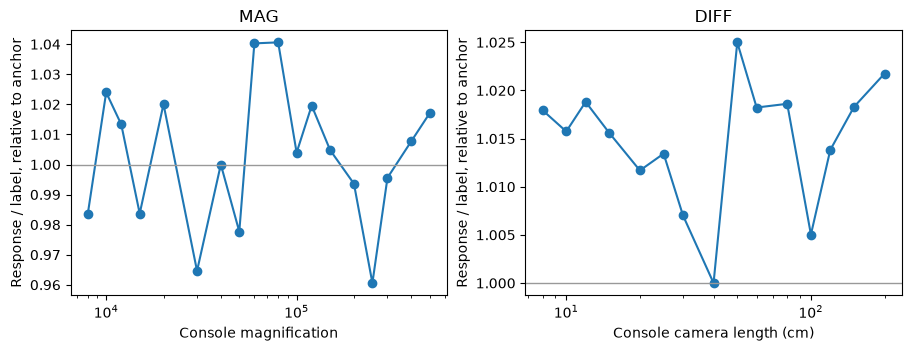

In [4]:
@jax.jit
def projection(c, p):
    return position_and_angle_response(column(c, p)[SPECIMEN_INDEX+1:], source_z=0., voltage=VOLTAGE)

fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), layout="constrained")
for ax, rows, mode, anchor in zip(axes, (mag, diff), ("MAG", "DIFF"), (40000, 40)):
    labels = np.array(list(rows))
    a, b = np.array([projection(readbacks(row), p) for row in rows.values()]).T
    scale = abs(a if mode == "MAG" else b) / labels
    ax.semilogx(labels, scale / scale[labels == anchor], "o-")
    ax.axhline(1, color="0.6", lw=1)
    ax.set(xlabel="Console magnification" if mode == "MAG" else "Console camera length (cm)",
           ylabel="Response / label, relative to anchor", title=mode)
    if mode == "MAG":
        print("MAG max |B/A| in units of L", f"{np.max(abs(b/a)):.2g}")
    else:
        print("DIFF max |A| (relative magnification)", f"{np.max(abs(a)):.2f}")
plt.show()

## A measured CLA1 kick at 40k, tested at the other MAG rows

The November 10 MAG sweep saved a $2\times2$ pixel-per-DAC matrix at each row together with CL1, CL3 and CLA1. Match the other settings by magnification to the November 17 presets. The neighboring 40k acquisition on November 10 read CM at 26624 and OLf at 38938. The sweep omitted these readbacks, so use the neighboring CM as an assumption. The objective prior was fitted at OLf 39269. These cross-session substitutions limit what this check establishes. The slope test cancels the baseline beam position. It cannot test absolute centroids.

At 40k the unknown CLA1 matrix enters linearly. Solve two linear systems, one for each measured axis. All other MAG slope measurements are held out from **this kick calibration**. The projector prior has already seen the nominal row labels. We exclude saturated-PL1 25k and rows marked unsuccessful in the acquisition summary.

Measured +100 CLA1 x DAC at 40k moves [column, row] px [-5.582 -8.142]
16 held-out matrices: median relative error 2.6%, maximum 9.1% at MAG 8,000.


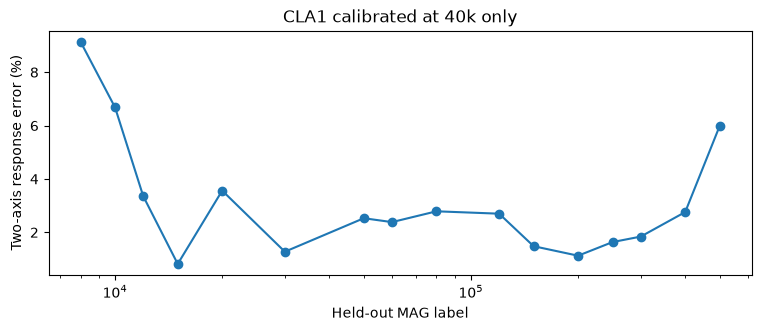

In [5]:
archive_path = here / "recordings/2026-11-10/beam_per_magnification.zip"
if not archive_path.exists():
    archive_path = here / "beam_per_magnification.zip"
with zipfile.ZipFile(archive_path) as archive:
    table_name = next(n for n in archive.namelist() if "beam_per_magnification_" in n and n.endswith("table.csv"))
    sweep = list(csv.DictReader(io.StringIO(archive.read(table_name).decode())))
    adjacent = json.loads(archive.read(next(n for n in archive.namelist() if n.endswith("modes.json"))))["MAG 40k"]

measured, controls = {}, {}
for item in sweep:
    label = int(item["magnification"])
    if label in mag and item["good"] == "True":
        row = dict(mag[label], CL1=int(item["CL1"]), CL3=int(item["CL3"]), CM=adjacent["lenses"]["CM"],
                   CLA1=[int(item["CLA1_x"]), int(item["CLA1_y"])])
        controls[label] = readbacks(row)
        measured[label] = np.array(json.loads(item["px_per_cla1_unit"]))

@jax.jit
def cla1_response(c, p):
    return jax.jacfwd(lambda dac: predict(dict(c, CLA1=dac), p)[:2])(c["CLA1"])

nominal_gain = p["kick_matrix"][0]
optical_map = cla1_response(controls[40000], p) @ jnp.linalg.inv(nominal_gain)
cla_gain = jnp.linalg.solve(optical_map, measured[40000])
kick_fit = dict(p, kick_matrix=p["kick_matrix"].at[0].set(cla_gain))

test_labels = np.array([m for m in measured if m != 40000])
actual = np.stack([measured[m] for m in test_labels])
predicted = np.stack([cla1_response(controls[m], kick_fit) for m in test_labels])
relative = np.linalg.norm(predicted - actual, axis=(1,2)) / np.linalg.norm(actual, axis=(1,2))
assert np.allclose(cla1_response(controls[40000], kick_fit), measured[40000])
print("Measured +100 CLA1 x DAC at 40k moves [column, row] px", 100 * measured[40000][:, 0])
print(f"{len(relative)} held-out matrices: median relative error {np.median(relative):.1%}, "
      f"maximum {relative.max():.1%} at MAG {test_labels[relative.argmax()]:,}.")
fig, ax = plt.subplots(figsize=(7.5, 3.2), layout="constrained")
ax.semilogx(test_labels, 100 * relative, "o-")
ax.set(xlabel="Held-out MAG label", ylabel="Two-axis response error (%)",
       title="CLA1 calibrated at 40k only"); plt.show()

The same local Jacobian can invert a small requested displacement. Below, round to integer DACs, check both axes against their limits, and re-predict the movement. A microscope run also needs a usable initial beam and a measured endpoint. The width and absolute offset need independent calibration.

In [6]:
goal_px = np.array([6., -3.])
here40 = controls[40000]
step = np.rint(np.linalg.solve(cla1_response(here40, kick_fit), goal_px)).astype(int)
next_dac = here40["CLA1"] + step
assert np.all((next_dac >= 0) & (next_dac <= 65535))
movement = beam(dict(here40, CLA1=next_dac), kick_fit) - beam(here40, kick_fit)
print("Requested px", goal_px, "   CLA1 change", step, "   model displacement px", np.round(movement[:2], 3))

Requested px [ 6. -3.]    CLA1 change [ -3 -69]    model displacement px [ 6.041 -3.021]


## Does the condenser predict the measured parallel-beam settings?

Five files in `calimages.zip` identify the CL3 DAC at which the operator saw parallel illumination, one per spot. CM was 26624 throughout. For a point source, parallel illumination means the outgoing slope of a ray launched at unit slope is zero. Remove the known round-lens rotation to get its signed radial slope. At fixed CL1 and CM this slope is affine in CL3 DAC squared, so two traces give the zero directly. A negative squared root means the current model cannot make a parallel beam at any physical CL3 excitation there.

Fix CM strength and all positions. Fit just the positive CL1 and CL3 strengths to spots 0, 1, 3 and 4. Spot 2 is a blind interpolation. Give the fit several starting points because a condenser can make extra crossovers. Fit the squared DAC, divided by twice the observed DAC, so residuals near the solution are in approximate DAC units. Only the training spots enter the start selection and the gradient steps.

In [7]:
with zipfile.ZipFile(here / "calimages.zip") as archive:
    parallel = []
    for name in sorted(name for name in archive.namelist() if "parallel" in name and name.endswith(".npz")):
        with np.load(io.BytesIO(archive.read(name))) as frame:
            parallel.append([int(frame[key]) for key in ("cl1", "cl3", "clm")])
parallel = np.array(sorted(parallel))
assert parallel.shape == (5, 3) and np.all(parallel[:, 2] == 26624)
cl1_obs, cl3_obs, cm_obs = parallel.T
train = np.array([0, 1, 3, 4])
source = Ray(x=0., y=0., dx=1., dy=0., z=p["source_z"], pathlength=0., voltage=VOLTAGE)

def parallel_cl3_squared(cl1, cm, log_gain):
    fitted = dict(p, Gc=p["Gc"].at[:2].multiply(jnp.exp(log_gain)))
    slopes = []
    for cl3 in (20000., 40000.):
        c = dict(c40, CL1=cl1, CL3=cl3, CM=cm)
        ray = run_to_end(source, column(c, fitted)[:SPECIMEN_INDEX+1])
        angle = compute_Rc_from_voltage(VOLTAGE) * (p["turns"][:3] @ jnp.array([cl1, cl3, cm]))
        slopes.append(ray.dx * jnp.cos(angle) + ray.dy * jnp.sin(angle))
    first, second = slopes
    return 20000.**2 - first * (40000.**2 - 20000.**2) / (second - first)

all_spots = jax.jit(jax.vmap(parallel_cl3_squared, in_axes=(0, 0, None)))
@jax.jit
def residual(g):
    squared = all_spots(cl1_obs[train], cm_obs[train], g)
    return (squared - cl3_obs[train]**2) / (2 * cl3_obs[train])

derivative = jax.jit(jax.jacfwd(residual))
starts = np.stack(np.meshgrid(np.linspace(-1.3, 1.3, 40), np.linspace(-1.3, 1.3, 20)), axis=-1).reshape(-1, 2)
costs = np.sum(np.asarray(jax.vmap(residual)(starts))**2, axis=1)
gain = starts[np.nanargmin(costs)]
damping = 0.01
for iteration in range(30):
    r, J = residual(gain), derivative(gain)
    H = J.T @ J
    step = np.linalg.solve(H + damping * np.diag(np.diag(H)), -J.T @ r)
    trial = gain + step
    if np.linalg.norm(residual(trial)) < np.linalg.norm(r):
        gain, damping = trial, max(damping / 3, 1e-9)
    else:
        damping = min(damping * 5, 1e9)

squared = np.asarray(all_spots(cl1_obs, cm_obs, gain))
assert np.all(squared > 0)
root = np.sqrt(squared)
print("Fitted / starting [CL1, CL3] strengths", np.round(np.exp(gain), 3))
print("Spot    recorded CL3    predicted CL3    difference (DAC)")
for i, value in enumerate(cl3_obs):
    print(f"{i:4d}    {value:12d}    {root[i]:13.0f}    {root[i]-value:+10.0f}", "held out" if i == 2 else "")
condenser_fit = dict(kick_fit, Gc=kick_fit["Gc"].at[:2].multiply(np.exp(gain)))

Fitted / starting [CL1, CL3] strengths [1.648 0.418]
Spot    recorded CL3    predicted CL3    difference (DAC)
   0           37805            37897           +92 
   1           33600            33353          -247 
   2           31214            31107          -107 held out
   3           29758            29770           +12 
   4           28750            28897          +147 


The inferred strengths depend on the chosen source plane, the fixed corrector relay and CM. These five operator-selected parallel settings provide a check on the crossover as a function of spot at one CM setting. To validate beam width at alpha 0, vary CL3 on both sides of crossover and measure unclipped widths at a MAG and a DIFF row. This samples the position and angular spread of the same beam. Fit the source widths, then hold out an entire spot or CL3 interval. Missing projector readbacks in the other calibration images preclude treating them as full-column training frames.

## Can the console fit predict a lens wobble on the real microscope?

The 10 November recording supplies a harder test than changing a magnification label. At MAG 40k, CLA1 steers the beam. At DIFF 40 cm, CLA2 steers it. At each setting the operator measured the same coil along both axes. Fit on the opening reference and the positive step of each projection lens, then predict every negative step. The score is the two-dimensional error in the half-displacement between the two kicked frames, in pixels at the actual kick used. Differencing removes the changing zero of the beam.

For round optics TemGym gives two complex numbers per setting, $A$ for a specimen shift and $B$ for a specimen tilt. The coil can produce both. Each axis has two unknown complex gains, shared across the settings of its mode. As an empirical comparison, use the positive wobble of each lens to measure how that coil response changes per lens DAC.

In [8]:
from itertools import groupby
from neoarm_forward import HERE

archive_dir = HERE / "recordings/2026-11-10"
with zipfile.ZipFile(archive_dir / "imaging-system-fitting-40k-40cm.zip") as archive:
    name = next(n for n in archive.namelist() if n.endswith("/table.csv"))
    frames = list(csv.DictReader(io.StringIO(archive.read(name).decode())))

projectors = ("IL1", "IL2", "IL3", "PL1")
console = json.loads((HERE / "recordings/2026-11-17/console_tables.json").read_text())
home = next(r for r in console["rows"]["MAG"] if r["mag"][0] == 40000)
start_shape = parameters(home)

def projection_ab(dac, shape):
    controls = readbacks(home) | dict(zip(projectors, dac))
    return jnp.stack(projection(controls, shape))

blocks = []
for (mode, name), group in groupby(frames, key=lambda r: (r["mode"], r["setting"])):
    rows = list(group)
    roles = [r["role"] for r in rows]
    if roles != ["not deflected", "deflected +", "deflected -", "deflected +", "deflected -"]:
        continue
    if any(r["beam_usable"] != "True" for r in rows):
        continue
    assert [r["direction"] for r in rows[1:]] == ["x", "x", "y", "y"]
    coil = rows[1]["deflector"]
    xy = np.array([complex(float(r["beam_x_px"]), float(r["beam_y_px"])) for r in rows])
    span = np.array([float(rows[i][coil + "_" + axis]) - float(rows[i+1][coil + "_" + axis])
                     for i, axis in [(1, "x"), (3, "y")]])
    dac = np.array([float(rows[0][k]) for k in projectors])
    blocks.append(dict(mode=mode, name=name, dac=dac, zero=xy[0], kick=span/2, gain=(xy[[1, 3]] - xy[[2, 4]]) / span))

In [9]:
ab_batch = jax.jit(jax.vmap(projection_ab, in_axes=(0, None)))
for mode in ("MAG 40k", "DIFF 40 cm"):
    group = [b for b in blocks if b["mode"] == mode]
    references = [b for b in group if b["name"].endswith(" row")]
    base = references[0]
    print(f"{mode}, opening-to-closing reference motion {abs(references[-1]['zero'] - base['zero']):.2f} px")
    train = [base] + [b for b in group if " +" in b["name"]]
    test = [b for b in group if " -" in b["name"]]
    def responses(rows):
        return np.asarray(ab_batch(jnp.array([b["dac"] for b in rows]), start_shape))

    coil_gains = np.linalg.lstsq(responses(train), [b["gain"] for b in train], rcond=None)[0]
    # Four positive wobbles independently measure the derivative along four lens controls.
    lens_steps = np.stack([b["dac"] - base["dac"] for b in train[1:]])
    gain_change = np.stack([b["gain"] - base["gain"] for b in train[1:]])
    slope = np.linalg.solve(lens_steps, gain_change)
    delta = np.stack([b["dac"] - base["dac"] for b in test])
    measured = np.stack([b["gain"] for b in test])
    kick = np.stack([b["kick"] for b in test])
    print(f"{mode}, {len(test)} held-out settings, median displacement {np.median(abs(measured*kick)):.1f} px")
    for label, pred in [("fixed response", base["gain"]), ("TemGym A and B", responses(test) @ coil_gains),
                        ("measured lens slopes", base["gain"] + delta @ slope)]:
        print(f"  {label:23} {np.sqrt(np.mean(abs((pred-measured)*kick)**2)):5.2f} px RMS")

MAG 40k, opening-to-closing reference motion 1.32 px


MAG 40k, 4 held-out settings, median displacement 112.2 px


  fixed response          15.58 px RMS
  TemGym A and B          13.75 px RMS
  measured lens slopes     2.05 px RMS
DIFF 40 cm, opening-to-closing reference motion 2.36 px
DIFF 40 cm, 4 held-out settings, median displacement 97.6 px
  fixed response          10.06 px RMS
  TemGym A and B           4.38 px RMS
  measured lens slopes     0.64 px RMS


The measured slopes give a practical reason to acquire a kicked frame during a lens wobble. They capture a lens changing the steering gain. They were tested here at only two rows, with one lens changed at a time and one coil per mode. The opening and closing references moved even at the same nominal lens setting. These two repeats cannot distinguish time drift from hysteresis, but they provide a scale for interpreting absolute landing errors on this instrument. An absolute prediction also needs a separate check on compound moves.

## From detector pixels to lens positions

Write the transverse transfer from specimen to camera as $x_d=A x_s+L\,\hat B\,\theta_s$. Here $x_d$ and $x_s$ are lengths, $L$ is the specimen-to-SightX distance and $\hat B$ is the tilt response of the column traced with SightX at 1. A frame reports $x_d/p$, where $p$ is the effective length of one **binned** pixel at the screen. Unknown steering gains can absorb changes in these scales.

A grating of known pitch $d_g$ gives $g_{px}=|A|d_g/p$. The radius of an indexed gold ring gives $r_{px}=L|\hat B|\theta_{111}/p$, with $\theta_{111}\simeq\lambda/d_{111}$ at the recorded voltage. Thus a calibrated pixel pitch and an angular ruler set $L$ **conditional on the fitted shape**. The grating independently checks the magnification. If $p$ is unknown, the two rulers jointly set it and $L$ conditional on that same shape. A nominal screen diameter only gives $p$ when the imaged diameter in binned pixels is measured. The console's diffraction label is an effective camera length. [JEOL camera-constant definition](https://www.jeol.com/words/emterms/20121023.014459.php)

This example uses the existing **two-camera simulator rehearsal** and its saved joint fit. Strip the metric scale out of that fit, then reconstruct it from the SightX grating and ring measurements. The fit already saw these rulers, so this is an arithmetic and units check. For a copied physical recording, set the folder and the measured binned pitch in the cell below. It reads the recorded voltage and four projection DACs. Replace `ruler_shape` with the independently validated specimen-to-screen shape before interpreting the lens positions. Keep a ruler setting out of the shape fit to test the result.

In [10]:
from temgym_core.constants import energy2wavelength

# To use a copied physical recording, enter its folder and verified binned screen pitch (metres).
new_ruler_folder = None
screen_pitch_m = None
if new_ruler_folder is None:
    # The earlier fit supplies a shape for this particular simulated instrument.
    paired = json.loads((HERE / "results/two_cameras/model.json").read_text())
    assert paired["simulated"] and paired["rulers"]
    shape = paired["numbers"]["lenses"]
    gaps_m = np.exp(shape["log_gaps"])
    unit = gaps_m.sum()
    zeta = np.cumsum(gaps_m) / unit
    # In units of L, z, f and Tc divide by L; Gc multiplies by L since 1/f ∝ Gc.
    ruler_shape = start_shape | dict(
        objective_f=paired["objective_focal_length_m"] / unit, objective_z=zeta[0],
        z_lens=start_shape["z_lens"].at[3:].set(zeta[1:5]),
        Gc=start_shape["Gc"].at[3:].set(unit * np.exp(shape["log_Gc"])),
        Tc=start_shape["Tc"].at[3:].set(np.exp(shape["log_Tc"]) / unit),
        turns=start_shape["turns"].at[3:].set(shape["ampere_turns_per_unit"]),
        phi_a=jnp.zeros(4), phi_b=jnp.zeros(4),
    )
    ruler_dir = HERE / paired["recording"]
    voltage = paired["voltage_v"]
    camera = paired["cameras"][0]
    effective_pixel = paired["pixel_m"][0]
else:
    ruler_dir = Path(new_ruler_folder)
    info = json.loads((ruler_dir / "console.json").read_text())
    voltage = float(info["at the start"]["ht_v"])
    camera = info["about this recording"]["cameras"][0]
    if voltage != VOLTAGE or screen_pitch_m is None or not np.isfinite(screen_pitch_m) or screen_pitch_m <= 0:
        raise ValueError("This column needs its recorded 200 kV setting and a verified binned screen pitch in metres")
    effective_pixel = screen_pitch_m
    ruler_shape = start_shape  # replace with the independently validated specimen-to-screen shape when available
    zeta = np.r_[ruler_shape["objective_z"], ruler_shape["z_lens"][3:], 1.]
    print("Conditional scale using the supplied dimensionless column. Check the grating and ring results across rows.")
with (ruler_dir / "table.csv").open() as f:
    rulers = [r for r in csv.DictReader(f) if r["camera"] == camera
              and r["role"] in ("gold rings", "grating")
              and float(r.get("ring_radius_px") or r.get("grating_pitch_px") or "nan") > 0]
if {r["role"] for r in rulers} != {"gold rings", "grating"}:
    raise ValueError("Need valid SightX gold-ring radii and grating pitches in the recording")
ab = np.asarray(ab_batch(jnp.array([[float(r[k]) for k in projectors] for r in rulers]), ruler_shape))
pitch_m = 1e-3 / 2160
theta = float(energy2wavelength(voltage)) / (0.40782e-9 / np.sqrt(3))
scale_estimates = []
for r, (a, b_hat) in zip(rulers, ab):
    if r["role"] == "grating":
        pixel = abs(a) * pitch_m / float(r["grating_pitch_px"])
        print(f'{r["setting"]}: grating implies {pixel*1e6:.2f} µm/px (supplied {effective_pixel*1e6:g})')
    else:
        length = float(r["ring_radius_px"]) * effective_pixel / (theta * abs(b_hat))
        scale_estimates.append(length)
        print(f'{r["setting"]}: ring implies L = {length*1000:.2f} mm')
if len(scale_estimates) < 2:
    raise ValueError("Record gold at two camera lengths to check agreement before reporting L")
scale = np.median(scale_estimates)
print("Conditional on this shape. Same scale applied to the four effective lens centres (mm):")
for name, place in zip(projectors, scale * zeta[1:5]):
    print(f"{name:4} {1000*place:7.2f}")

DIFF 40: ring implies L = 798.26 mm
DIFF 80: ring implies L = 798.70 mm
MAG 8000: grating implies 110.06 µm/px (supplied 110)
MAG 12000: grating implies 109.97 µm/px (supplied 110)
Conditional on this shape. Same scale applied to the four effective lens centres (mm):
IL1   148.87
IL2   218.56
IL3   298.35
PL1   418.30


**What would pin an individual lens on the real NEOARM?** A value $z_i=L\zeta_i$ inherits the uncertainty in both factors. A ruler pins a length scale. Several arrangements of lenses can still send almost the same rays to one screen. A second detector a distance $s$ downstream also sees the exit slope through $x_2=x_1+s\theta_1$ after both cameras are registered. Measure symmetric shift and tilt kicks on both cameras at the same lens readbacks. Keep the upstream illumination fixed within a pair or check that its measured differential response repeats. Normal rows plus a small number of usable PL1 changes give independent measurements of the transfer. Record gold rings in DIFF, a grating in MAG and a held-back setting on each camera. The existing [two-camera acquisition](at_the_microscope/record_two_cameras.py) and [design study](two_cameras_design.ipynb) lay out the sequence.

The steering fit in the companion notebook absorbs the transfer up to IL1 into its fitted input gains. The gold scattering angle and grating pitch are defined at the specimen. Reinstate the specimen, fixed objective and flight to IL1 when evaluating the ruler responses.

When those frames exist, fit ordered positive axial gaps, the shared lens strengths, the camera registration and separation, and the steering gains jointly to both cameras and rulers. Reuse the damped JAX fit in the companion notebook. Start from several plausible columns, withhold whole rows, and profile each gap while refitting the remaining parameters. Report a physical position only to the precision shared by solutions that reproduce the independent measurements. In the archived rehearsal the joint fit estimated **5–8 mm** local uncertainties for IL1–PL1. These refer to effective optical planes. Establishing mechanical polepiece coordinates requires an independent mechanical reference. Condenser and source positions need upstream information or additional illumination constraints.